In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder

# Cari dataset baik saat notebook dijalankan dari root proyek maupun folder notebook.
data_candidates = [
    Path("data/komdigi_hoaks.csv"),
    Path("../data/komdigi_hoaks.csv"),
    Path("../../data/komdigi_hoaks.csv"),
    Path("../../../data/komdigi_hoaks.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("File komdigi_hoaks.csv tidak ditemukan.")

df = pd.read_csv(data_path)
print(f"Lokasi dataset: {data_path.resolve()}")
print("Ukuran awal:", df.shape)

# URL dipilih sebagai kunci duplikasi; ID dan kolom metadata bukan fitur prediktor.
df = df.drop_duplicates(subset="url", keep="first").copy()
text_columns = ["title", "excerpt", "body_text"]
df[text_columns] = df[text_columns].fillna("").astype(str)
df["article_text"] = (
    df[text_columns]
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df["topics"] = df["topics"].str.strip()

# Target adalah topik artikel, bukan label klaim benar atau salah.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df["topics"])
X_train, X_test, y_train, y_test = train_test_split(
    df["article_text"],
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)
print("Baris setelah menghapus URL duplikat:", len(df))
print("Pemetaan label:", dict(enumerate(label_encoder.classes_)))

# TF-IDF menghasilkan fitur teks nonnegatif, sehingga sesuai untuk seleksi chi-square.
pipe_filter = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=10000)),
    ("sel", SelectKBest(score_func=chi2, k=300)),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])
pipe_filter.fit(X_train, y_train)
pred = pipe_filter.predict(X_test)
print("\n=== TF-IDF + Chi-square + Logistic Regression ===")
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print(classification_report(
    y_test,
    pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0,
))

feature_names = pipe_filter.named_steps["tfidf"].get_feature_names_out()
selector = pipe_filter.named_steps["sel"]
selected_names = feature_names[selector.get_support()]
selected_scores = selector.scores_[selector.get_support()]
top_features = sorted(
    zip(selected_names, selected_scores),
    key=lambda item: item[1],
    reverse=True,
)[:20]
print("20 fitur terpilih dengan skor chi-square tertinggi:")
print(top_features)

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran awal: (4176, 13)
Baris setelah menghapus URL duplikat: 4162
Pemetaan label: {0: 'Hoaks', 1: 'Kesehatan', 2: 'Masyarakat Digital', 3: 'Pejabat Publik', 4: 'Penipuan', 5: 'Program/Kebijakan'}

=== TF-IDF + Chi-square + Logistic Regression ===
Accuracy: 0.6098
                    precision    recall  f1-score   support

             Hoaks       0.94      0.61      0.74       705
         Kesehatan       0.16      0.45      0.23        11
Masyarakat Digital       0.07      0.10      0.08        21
    Pejabat Publik       0.24      0.93      0.38        27
          Penipuan       0.27      0.81      0.41        57
 Program/Kebijakan       0.07      0.25      0.11        12

          accuracy                           0.61       833
         macro avg       0.29      0.52      0.32       833
      weighted avg       0.83      0.61      0.67       833

20 fitur terpilih dengan skor c

In [2]:
# Contoh matriks TF-IDF yang dibentuk dari artikel Komdigi.
from IPython.display import display

sample_articles = df.sort_values("topics").groupby("topics", as_index=False).head(1)
demo_text = sample_articles["article_text"].tolist()
demo_labels = sample_articles["topics"].tolist()
vectorizer_demo = TfidfVectorizer(max_features=30, ngram_range=(1, 2), min_df=1)
tfidf_demo = vectorizer_demo.fit_transform(demo_text)

tfidf_table = pd.DataFrame(
    tfidf_demo.toarray(),
    index=demo_labels,
    columns=vectorizer_demo.get_feature_names_out(),
)
print("Ukuran matriks TF-IDF:", tfidf_demo.shape)
display(tfidf_table.round(3))

Ukuran matriks TF-IDF: (6, 30)


,2026,adalah,bahwa,beredar,bsu,com,counter,dan,dari,di,...,ninja,pintu,resmi,september,september 2026,situs,tersebut,tidak,unggahan,yang
Hoaks,0.543,0.037,0.000,0.037,0.662,0.098,0.037,0.110,0.037,0.000,...,0.000,0.00,0.115,0.272,0.272,0.000,0.037,0.073,0.042,0.147
Kesehatan,0.000,0.104,0.325,0.104,0.000,0.000,0.104,0.417,0.104,0.139,...,0.000,0.00,0.000,0.000,0.000,0.000,0.209,0.209,0.241,0.626
Masyarakat Digital,0.000,0.035,0.163,0.035,0.000,0.140,0.035,0.035,0.035,0.187,...,0.629,0.55,0.000,0.000,0.000,0.000,0.105,0.035,0.081,0.105
Pejabat Publik,0.000,0.080,0.250,0.240,0.000,0.214,0.080,0.320,0.240,0.214,...,0.000,0.00,0.000,0.000,0.000,0.000,0.080,0.160,0.092,0.320
Penipuan,0.000,0.074,0.000,0.074,0.000,0.099,0.074,0.148,0.074,0.000,...,0.000,0.00,0.231,0.000,0.000,0.822,0.148,0.074,0.000,0.074
Program/Kebijakan,0.359,0.065,0.000,0.130,0.000,0.000,0.065,0.194,0.065,0.173,...,0.000,0.00,0.202,0.359,0.359,0.120,0.065,0.130,0.075,0.065


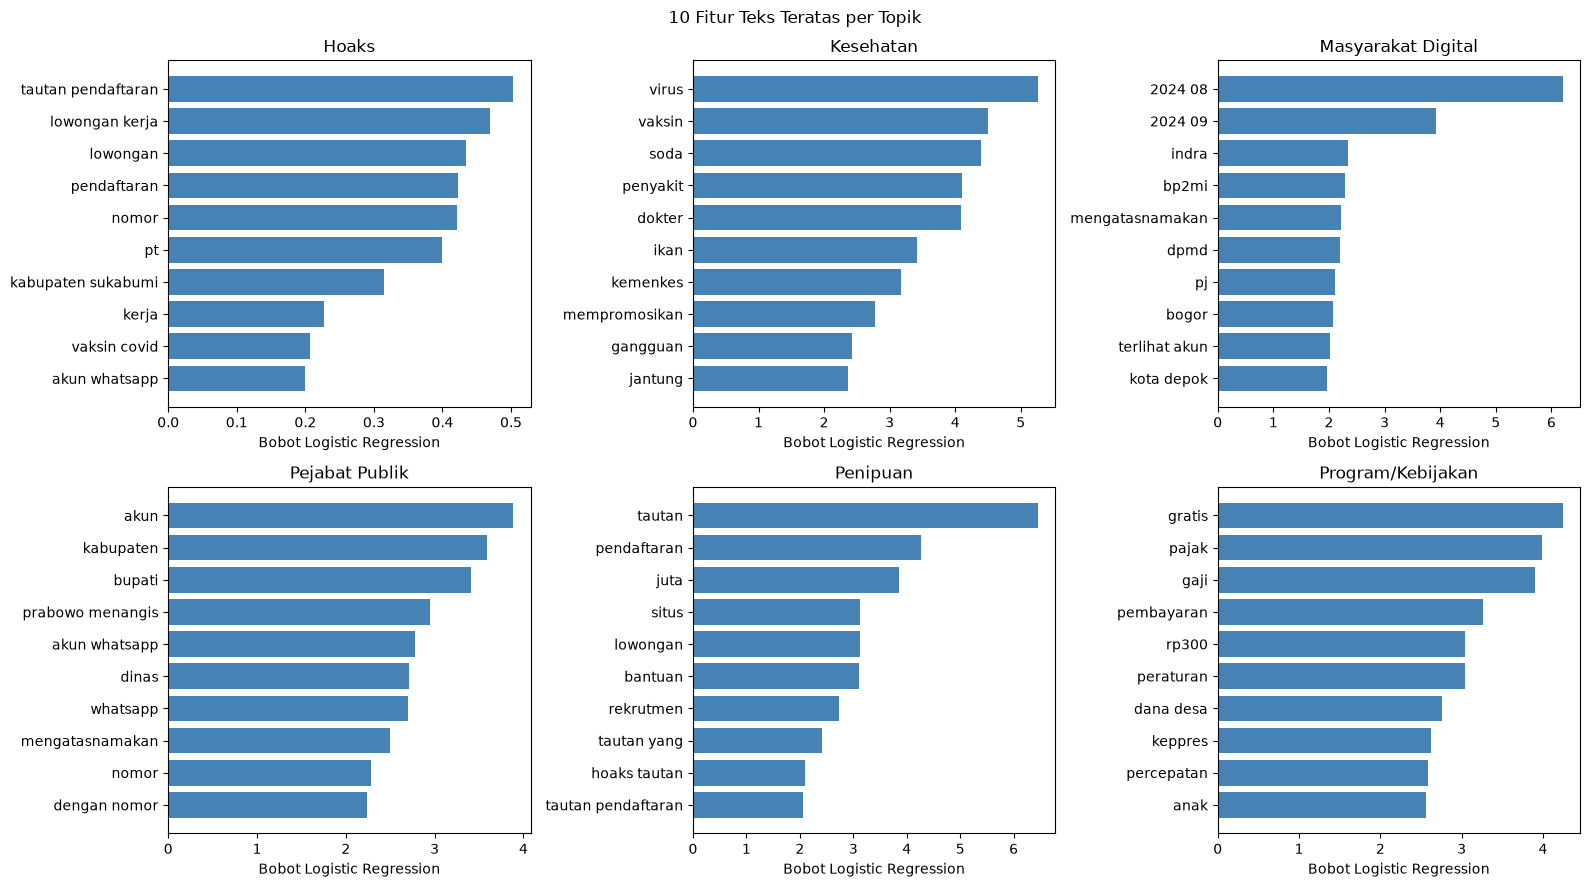

In [3]:
# Kata/frasa dengan bobot positif tertinggi untuk tiap topik.
classifier = pipe_filter.named_steps["clf"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for class_index, (ax, class_name) in enumerate(zip(axes.flat, label_encoder.classes_)):
    top_indices = np.argsort(classifier.coef_[class_index])[-10:][::-1]
    terms = selected_names[top_indices]
    weights = classifier.coef_[class_index][top_indices]
    ax.barh(terms[::-1], weights[::-1], color="steelblue")
    ax.set_title(class_name)
    ax.set_xlabel("Bobot Logistic Regression")

fig.suptitle("10 Fitur Teks Teratas per Topik")
plt.tight_layout()
plt.show()

# Tugas Praktikum: Ekstraksi dan Seleksi Fitur Teks

Gunakan dataset `komdigi_hoaks.csv` untuk mengelompokkan artikel berdasarkan kolom `topics`.

1. Gabungkan `title`, `excerpt`, dan `body_text` menjadi fitur teks; isi ringkasan yang kosong dengan teks kosong.
2. Buang artikel dengan URL duplikat dan pisahkan fitur dari target.
3. Bagi data menjadi data latih dan data uji dengan rasio 80:20 serta stratifikasi berdasarkan topik.
4. Ubah teks menjadi fitur TF-IDF, lakukan seleksi fitur menggunakan chi-square, lalu latih Logistic Regression.
5. Evaluasi model dengan accuracy dan classification report serta amati fitur teks terpilih.

`topics` adalah label kategori topik artikel, bukan label kebenaran klaim. Kolom `category` tidak digunakan karena seluruh baris memiliki kategori sumber yang sama. ID, URL, tanggal, dan kolom metadata lain tidak dipakai sebagai prediktor.

,topik,jumlah_train,persen_train,jumlah_test,persen_test
0,Hoaks,2819,84.68,705,84.63
1,Kesehatan,45,1.35,11,1.32
2,Masyarakat Digital,81,2.43,21,2.52
3,Pejabat Publik,108,3.24,27,3.24
4,Penipuan,229,6.88,57,6.84
5,Program/Kebijakan,47,1.41,12,1.44


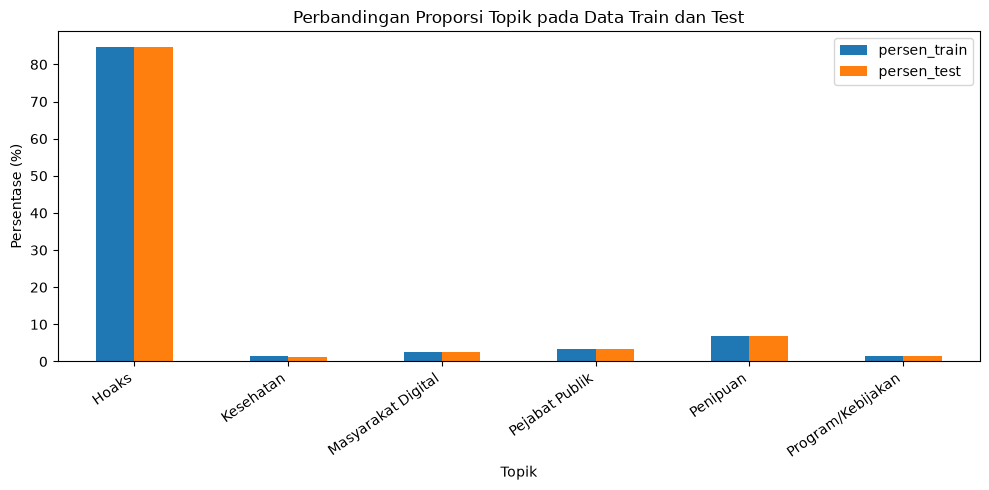

In [4]:
# Verifikasi bahwa proporsi topik tetap terjaga pada split stratified.
train_counts = np.bincount(y_train, minlength=len(label_encoder.classes_))
test_counts = np.bincount(y_test, minlength=len(label_encoder.classes_))
split_summary = pd.DataFrame({
    "topik": label_encoder.classes_,
    "jumlah_train": train_counts,
    "persen_train": (train_counts / len(y_train) * 100).round(2),
    "jumlah_test": test_counts,
    "persen_test": (test_counts / len(y_test) * 100).round(2),
})
display(split_summary)

split_summary.set_index("topik")[["persen_train", "persen_test"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Perbandingan Proporsi Topik pada Data Train dan Test")
plt.xlabel("Topik")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()